In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
import glob

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
os.makedirs("IPL_Analysis/visualizations", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [3]:
import zipfile
import os

zip_path = "/content/ipl_male_json.zip"
extract_path = "/content/IPL_Analysis/raw_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("IPL dataset extracted successfully!")

IPL dataset extracted successfully!


In [4]:
json_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".json"):
            json_files.append(os.path.join(root, file))

print("Total IPL match files:", len(json_files))
print("Sample file:", json_files[0] if json_files else "No files found")

Total IPL match files: 1243
Sample file: /content/IPL_Analysis/raw_data/597999.json


In [5]:
# Locate all JSON match files
json_files = glob.glob(
    "/content/IPL_Analysis/raw_data/**/*.json",
    recursive=True
)

print("Total match files:", len(json_files))

Total match files: 1243


In [6]:
with open(json_files[0], "r") as file:
    sample_match = json.load(file)

print(json.dumps(sample_match, indent=4)[:3000])

{
    "meta": {
        "data_version": "1.3.0",
        "created": "2013-04-04",
        "revision": 2
    },
    "info": {
        "balls_per_over": 6,
        "city": "Bangalore",
        "dates": [
            "2013-04-04"
        ],
        "event": {
            "match_number": 2,
            "name": "Indian Premier League"
        },
        "gender": "male",
        "match_type": "T20",
        "officials": {
            "match_referees": [
                "AJ Pycroft"
            ],
            "reserve_umpires": [
                "KN Ananthapadmanabhan"
            ],
            "tv_umpires": [
                "K Srinath"
            ],
            "umpires": [
                "VA Kulkarni",
                "C Shamshuddin"
            ]
        },
        "outcome": {
            "by": {
                "runs": 2
            },
            "winner": "Royal Challengers Bangalore"
        },
        "overs": 20,
        "player_of_match": [
            "CH Gayle"
        ],
  

In [7]:
info = sample_match["info"]

print("Teams:", info.get("teams"))
print("Venue:", info.get("venue"))
print("Date:", info.get("dates"))
print("Toss:", info.get("toss"))
print("Outcome:", info.get("outcome"))

Teams: ['Royal Challengers Bangalore', 'Mumbai Indians']
Venue: M Chinnaswamy Stadium, Bangalore
Date: ['2013-04-04']
Toss: {'decision': 'field', 'winner': 'Mumbai Indians'}
Outcome: {'by': {'runs': 2}, 'winner': 'Royal Challengers Bangalore'}


In [8]:
all_teams = set()

for file_path in json_files:
    with open(file_path, "r") as file:
        match = json.load(file)

    teams = match["info"].get("teams", [])
    all_teams.update(teams)

print("Total unique teams:", len(all_teams))

print("\nTeams in IPL dataset:")
for team in sorted(all_teams):
    print(team)

Total unique teams: 19

Teams in IPL dataset:
Chennai Super Kings
Deccan Chargers
Delhi Capitals
Delhi Daredevils
Gujarat Lions
Gujarat Titans
Kings XI Punjab
Kochi Tuskers Kerala
Kolkata Knight Riders
Lucknow Super Giants
Mumbai Indians
Pune Warriors
Punjab Kings
Rajasthan Royals
Rising Pune Supergiant
Rising Pune Supergiants
Royal Challengers Bangalore
Royal Challengers Bengaluru
Sunrisers Hyderabad


In [30]:
matches = []

for file_path in json_files:
    with open(file_path, "r") as file:
        match = json.load(file)

    match_id = os.path.basename(file_path).replace(".json", "")

    info = match["info"]

    matches.append({
        "match_id": match_id,
        "date": info.get("dates", [None])[0],
        "venue": info.get("venue"),
        "city": info.get("city"),
        "team1": info.get("teams", [None, None])[0],
        "team2": info.get("teams", [None, None])[1],
        "toss_winner": info.get("toss", {}).get("winner"),
        "toss_decision": info.get("toss", {}).get("decision"),
        "winner": info.get("outcome", {}).get("winner"),
        "match_type": info.get("match_type")
    })

matches_df = pd.DataFrame(matches)

print("Match dataset created!")
print("Shape:", matches_df.shape)

matches_df.head()

Match dataset created!
Shape: (1243, 10)


,match_id,date,venue,city,team1,team2,toss_winner,toss_decision,winner,match_type
0,597999,2013-04-04,"M Chinnaswamy Stadium, Bangalore",Bangalore,Royal Challengers Bangalore,Mumbai Indians,Mumbai Indians,field,Royal Challengers Bangalore,T20
1,1359523,2023-05-06,MA Chidambaram Stadium,Chennai,Mumbai Indians,Chennai Super Kings,Chennai Super Kings,field,Chennai Super Kings,T20
2,1216546,2020-10-20,Dubai International Cricket Stadium,None,Delhi Capitals,Kings XI Punjab,Delhi Capitals,bat,Kings XI Punjab,T20
3,829743,2015-04-22,Andhra Cricket Association-Visakhapatnam Distr...,Visakhapatnam,Sunrisers Hyderabad,Kolkata Knight Riders,Kolkata Knight Riders,field,Sunrisers Hyderabad,T20
4,1529308,2026-05-20,"Eden Gardens, Kolkata",Kolkata,Mumbai Indians,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,T20


In [10]:
print("Total matches:", len(matches_df))

print("\nDataset information:")
matches_df.info()

print("\nMissing values:")
print(matches_df.isnull().sum())

print("\nUnique teams:")
print(pd.unique(matches_df[["team1", "team2"]].values.ravel()))

Total matches: 1243

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   date           1243 non-null   object
 1   venue          1243 non-null   object
 2   city           1192 non-null   object
 3   team1          1243 non-null   object
 4   team2          1243 non-null   object
 5   toss_winner    1243 non-null   object
 6   toss_decision  1243 non-null   object
 7   winner         1218 non-null   object
 8   match_type     1243 non-null   object
dtypes: object(9)
memory usage: 87.5+ KB

Missing values:
date              0
venue             0
city             51
team1             0
team2             0
toss_winner       0
toss_decision     0
winner           25
match_type        0
dtype: int64

Unique teams:
['Royal Challengers Bangalore' 'Mumbai Indians' 'Chennai Super Kings'
 'Delhi Capitals' 'Kings XI Punjab' 'Sunris

In [28]:
deliveries = []

for file_path in json_files:
    with open(file_path, "r") as file:
        match = json.load(file)

    match_id = os.path.basename(file_path).replace(".json", "")
    match_date = match["info"].get("dates", [None])[0]

    for innings_number, innings in enumerate(match["innings"], start=1):

        batting_team = innings.get("team")

        for over in innings.get("overs", []):
            over_number = over.get("over")

            for ball_number, delivery in enumerate(over.get("deliveries", []), start=1):

                runs = delivery.get("runs", {})
                wickets = delivery.get("wickets", [])

                deliveries.append({
                    "match_id": match_id,
                    "date": match_date,
                    "innings": innings_number,
                    "batting_team": batting_team,
                    "bowler": delivery.get("bowler"),
                    "batter": delivery.get("batter"),
                    "non_striker": delivery.get("non_striker"),
                    "over": over_number,
                    "ball": ball_number,
                    "batter_runs": runs.get("batter", 0),
                    "total_runs": runs.get("total", 0),
                    "extras": runs.get("total", 0) - runs.get("batter", 0),
                    "wicket": 1 if wickets else 0,
                    "dismissal": wickets[0].get("kind") if wickets else None
                })

deliveries_df = pd.DataFrame(deliveries)

print("Delivery dataset created successfully!")
print("Shape:", deliveries_df.shape)

deliveries_df.head()

Delivery dataset created successfully!
Shape: (295732, 14)


,match_id,date,innings,batting_team,bowler,batter,non_striker,over,ball,batter_runs,total_runs,extras,wicket,dismissal
0,597999,2013-04-04,1,Royal Challengers Bangalore,MG Johnson,CH Gayle,TM Dilshan,0,1,0,0,0,0,None
1,597999,2013-04-04,1,Royal Challengers Bangalore,MG Johnson,CH Gayle,TM Dilshan,0,2,0,0,0,0,None
2,597999,2013-04-04,1,Royal Challengers Bangalore,MG Johnson,CH Gayle,TM Dilshan,0,3,1,1,0,0,None
3,597999,2013-04-04,1,Royal Challengers Bangalore,MG Johnson,TM Dilshan,CH Gayle,0,4,0,0,0,0,None
4,597999,2013-04-04,1,Royal Challengers Bangalore,MG Johnson,TM Dilshan,CH Gayle,0,5,0,0,0,0,None


In [29]:
print("Total deliveries:", len(deliveries_df))

print("\nDataset information:")
deliveries_df.info()

print("\nMissing values:")
print(deliveries_df.isnull().sum())

print("\nStatistical summary:")
display(deliveries_df.describe())

Total deliveries: 295732

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295732 entries, 0 to 295731
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   match_id      295732 non-null  object
 1   date          295732 non-null  object
 2   innings       295732 non-null  int64 
 3   batting_team  295732 non-null  object
 4   bowler        295732 non-null  object
 5   batter        295732 non-null  object
 6   non_striker   295732 non-null  object
 7   over          295732 non-null  int64 
 8   ball          295732 non-null  int64 
 9   batter_runs   295732 non-null  int64 
 10  total_runs    295732 non-null  int64 
 11  extras        295732 non-null  int64 
 12  wicket        295732 non-null  int64 
 13  dismissal     14705 non-null   object
dtypes: int64(7), object(7)
memory usage: 31.6+ MB

Missing values:
match_id             0
date                 0
innings              0
batting_team     

,innings,over,ball,batter_runs,total_runs,extras,wicket
count,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000
mean,1.482728,9.190331,3.629195,1.290117,1.358453,0.068336,0.049724
std,0.502436,5.679690,1.819312,1.664418,1.650191,0.342939,0.217375
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,9.000000,4.000000,1.000000,1.000000,0.000000,0.000000
75%,2.000000,14.000000,5.000000,1.000000,1.000000,0.000000,0.000000
max,6.000000,19.000000,11.000000,6.000000,7.000000,7.000000,1.000000


In [13]:
team_wins = matches_df["winner"].value_counts()

print("IPL TEAM WINNING RECORDS")
display(team_wins.reset_index().rename(
    columns={"index": "Team", "winner": "Total Wins"}
))

IPL TEAM WINNING RECORDS


,Total Wins,count
0,Mumbai Indians,155
1,Chennai Super Kings,148
2,Kolkata Knight Riders,140
3,Rajasthan Royals,123
4,Royal Challengers Bangalore,114
5,Sunrisers Hyderabad,102
6,Kings XI Punjab,85
7,Delhi Daredevils,67
8,Delhi Capitals,58
9,Gujarat Titans,47


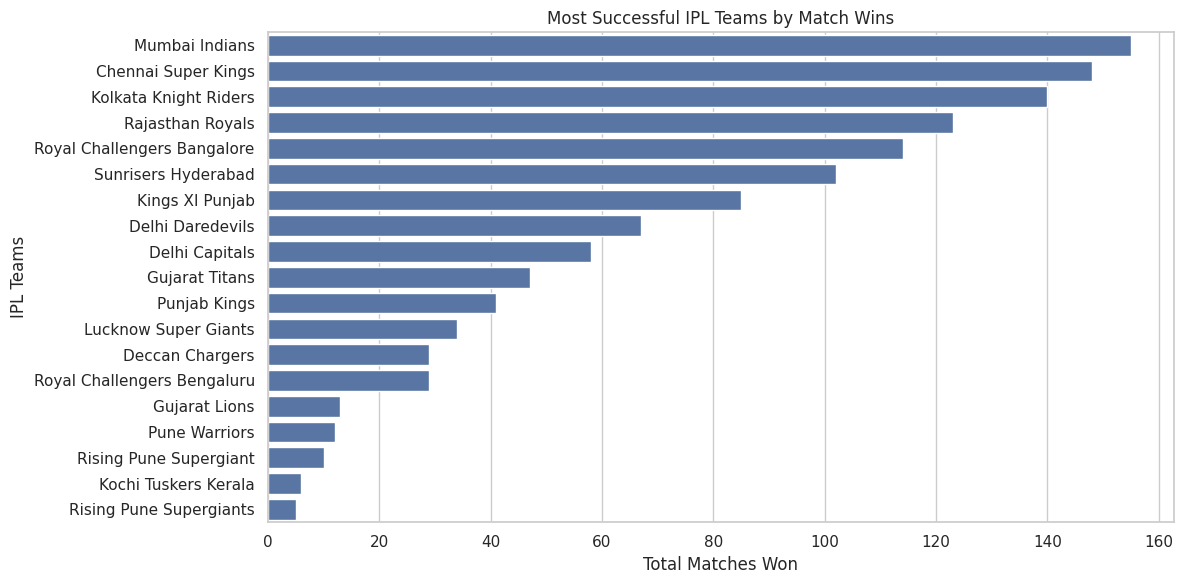

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=team_wins.values,
    y=team_wins.index
)

plt.title("Most Successful IPL Teams by Match Wins")
plt.xlabel("Total Matches Won")
plt.ylabel("IPL Teams")
plt.tight_layout()
plt.show()

In [15]:
team_matches = pd.concat([
    matches_df["team1"],
    matches_df["team2"]
]).value_counts()

team_performance = pd.DataFrame({
    "Matches Played": team_matches,
    "Matches Won": team_wins
}).fillna(0)

team_performance["Win Percentage"] = (
    team_performance["Matches Won"] /
    team_performance["Matches Played"] * 100
)

display(team_performance.sort_values(
    "Matches Won", ascending=False
).round(2))

,Matches Played,Matches Won,Win Percentage
Mumbai Indians,291,155,53.26
Chennai Super Kings,266,148,55.64
Kolkata Knight Riders,278,140,50.36
Rajasthan Royals,251,123,49.00
Royal Challengers Bangalore,240,114,47.50
Sunrisers Hyderabad,211,102,48.34
Kings XI Punjab,190,85,44.74
Delhi Daredevils,161,67,41.61
Delhi Capitals,120,58,48.33
Gujarat Titans,77,47,61.04


In [16]:
player_runs = (
    deliveries_df.groupby("batter")["batter_runs"]
    .sum()
    .sort_values(ascending=False)
)

top_10_batters = player_runs.head(10)

print("TOP 10 IPL RUN SCORERS")
display(top_10_batters.reset_index())

TOP 10 IPL RUN SCORERS


,batter,batter_runs
0,V Kohli,9346
1,RG Sharma,7331
2,S Dhawan,6769
3,DA Warner,6567
4,KL Rahul,5828
5,SK Raina,5536
6,MS Dhoni,5439
7,AM Rahane,5367
8,AB de Villiers,5181
9,SV Samson,5181


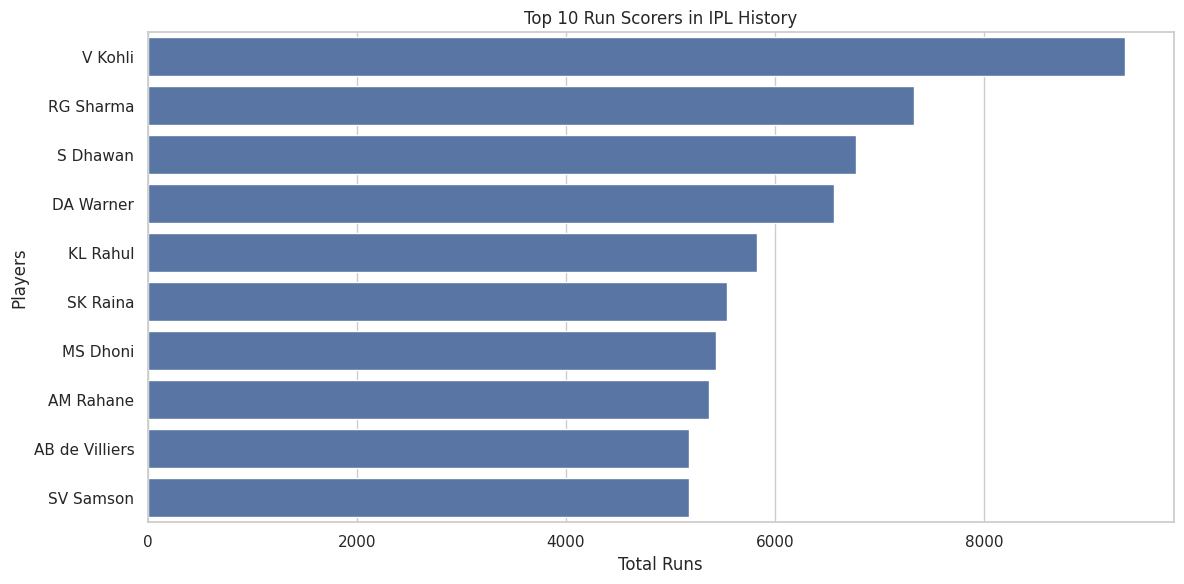

In [17]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_batters.values,
    y=top_10_batters.index
)

plt.title("Top 10 Run Scorers in IPL History")
plt.xlabel("Total Runs")
plt.ylabel("Players")
plt.tight_layout()
plt.show()

In [18]:
batting_stats = deliveries_df.groupby("batter").agg(
    Total_Runs=("batter_runs", "sum"),
    Balls_Faced=("batter_runs", "count")
)

batting_stats["Strike_Rate"] = (
    batting_stats["Total_Runs"] /
    batting_stats["Balls_Faced"] * 100
)

batting_stats = batting_stats.sort_values(
    "Total_Runs", ascending=False
)

display(batting_stats.head(10).round(2))

,Total_Runs,Balls_Faced,Strike_Rate
batter,,,
V Kohli,9346,7127,131.14
RG Sharma,7331,5659,129.55
S Dhawan,6769,5483,123.45
DA Warner,6567,4849,135.43
KL Rahul,5828,4302,135.47
SK Raina,5536,4177,132.54
MS Dhoni,5439,4101,132.63
AM Rahane,5367,4391,122.23
AB de Villiers,5181,3487,148.58


In [19]:
bowler_wicket_types = [
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket"
]

bowler_wickets = (
    deliveries_df[
        deliveries_df["dismissal"].isin(bowler_wicket_types)
    ]
    .groupby("bowler")["wicket"]
    .sum()
    .sort_values(ascending=False)
)

top_10_bowlers = bowler_wickets.head(10)

print("TOP 10 IPL WICKET-TAKERS")
display(top_10_bowlers.reset_index())

TOP 10 IPL WICKET-TAKERS


,bowler,wicket
0,YS Chahal,233
1,B Kumar,226
2,SP Narine,209
3,PP Chawla,192
4,JJ Bumrah,190
5,R Ashwin,187
6,DJ Bravo,183
7,RA Jadeja,180
8,Rashid Khan,179
9,A Mishra,174


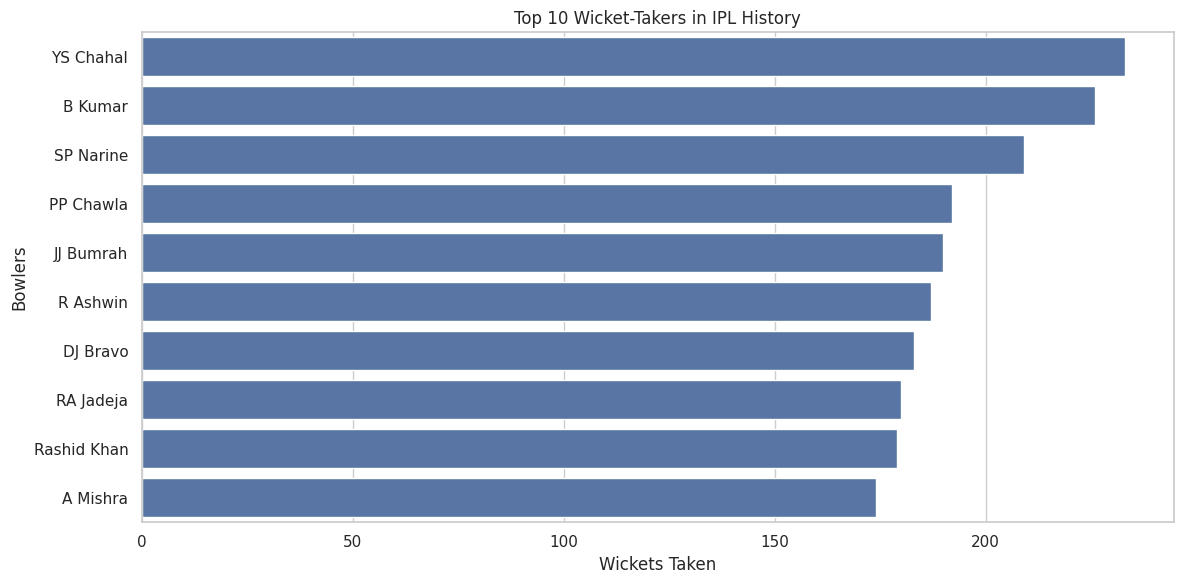

In [20]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_bowlers.values,
    y=top_10_bowlers.index
)

plt.title("Top 10 Wicket-Takers in IPL History")
plt.xlabel("Wickets Taken")
plt.ylabel("Bowlers")
plt.tight_layout()
plt.show()

In [21]:
bowling_stats = deliveries_df.groupby("bowler").agg(
    Total_Runs_Conceded=("total_runs", "sum"),
    Deliveries=("total_runs", "count")
)

bowling_stats["Wickets"] = bowler_wickets

bowling_stats["Overs"] = bowling_stats["Deliveries"] / 6

bowling_stats["Economy"] = (
    bowling_stats["Total_Runs_Conceded"] /
    bowling_stats["Overs"]
)

bowling_stats = bowling_stats.fillna(0)

display(
    bowling_stats.sort_values(
        "Wickets", ascending=False
    ).head(10).round(2)
)

,Total_Runs_Conceded,Deliveries,Wickets,Overs,Economy
bowler,,,,,
YS Chahal,5501,4167,233.0,694.50,7.92
B Kumar,6045,4769,226.0,794.83,7.61
SP Narine,5379,4730,209.0,788.33,6.82
PP Chawla,5179,3895,192.0,649.17,7.98
JJ Bumrah,4582,3792,190.0,632.00,7.25
R Ashwin,5721,4868,187.0,811.33,7.05
DJ Bravo,4436,3296,183.0,549.33,8.08
RA Jadeja,5525,4329,180.0,721.50,7.66
Rashid Khan,4390,3585,179.0,597.50,7.35


In [22]:
# Identify matches where toss winner also won the match
matches_df["Toss_Winner_Won"] = (
    matches_df["toss_winner"] == matches_df["winner"]
)

toss_results = matches_df["Toss_Winner_Won"].value_counts()

print("TOSS IMPACT ANALYSIS")
print("Toss winner also won:", toss_results.get(True, 0))
print("Toss winner lost:", toss_results.get(False, 0))

toss_win_percentage = (
    toss_results.get(True, 0) /
    matches_df["winner"].notna().sum()
) * 100

print("Toss-to-match win percentage:", round(toss_win_percentage, 2), "%")

TOSS IMPACT ANALYSIS
Toss winner also won: 628
Toss winner lost: 615
Toss-to-match win percentage: 51.56 %


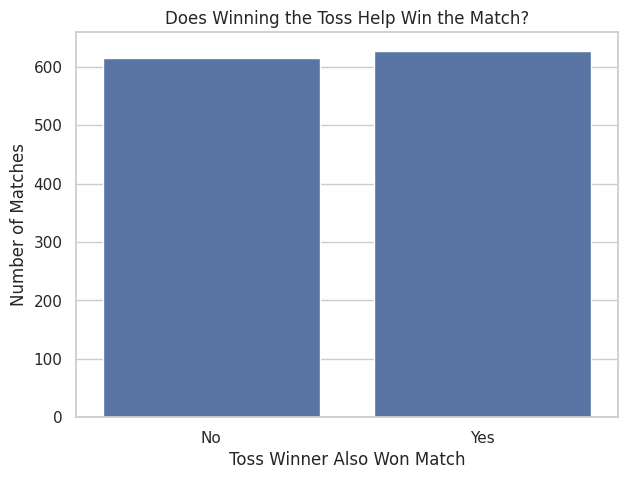

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=matches_df,
    x="Toss_Winner_Won"
)

plt.title("Does Winning the Toss Help Win the Match?")
plt.xlabel("Toss Winner Also Won Match")
plt.ylabel("Number of Matches")
plt.xticks([0, 1], ["No", "Yes"])

plt.show()

TOSS DECISIONS


,toss_decision,count
0,field,825
1,bat,418


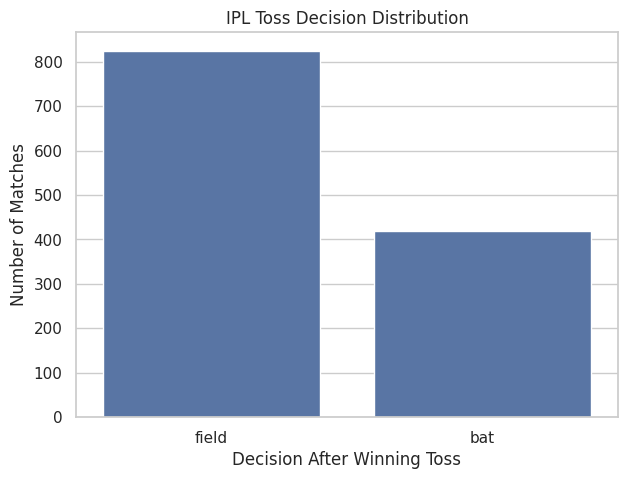

In [24]:
toss_decisions = matches_df["toss_decision"].value_counts()

print("TOSS DECISIONS")
display(toss_decisions.reset_index())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=matches_df,
    x="toss_decision"
)

plt.title("IPL Toss Decision Distribution")
plt.xlabel("Decision After Winning Toss")
plt.ylabel("Number of Matches")

plt.show()

In [25]:
# Create a match-to-venue mapping
venue_map = matches_df[["date", "team1", "team2", "venue"]].copy()

# Merge venue information into delivery data
venue_deliveries = deliveries_df.merge(
    venue_map,
    on="date",
    how="left"
)

print("Venue information merged!")
print(venue_deliveries[["venue", "total_runs"]].head())

Venue information merged!
                              venue  total_runs
0  M Chinnaswamy Stadium, Bangalore           0
1  M Chinnaswamy Stadium, Bangalore           0
2  M Chinnaswamy Stadium, Bangalore           1
3  M Chinnaswamy Stadium, Bangalore           0
4  M Chinnaswamy Stadium, Bangalore           0


In [31]:
venue_deliveries = deliveries_df.merge(
    matches_df[["match_id", "venue"]],
    on="match_id",
    how="left"
)

print("Venue merge completed!")
print("Missing venues:", venue_deliveries["venue"].isnull().sum())

Venue merge completed!
Missing venues: 0


In [32]:
venue_runs = (
    venue_deliveries.groupby("venue")["total_runs"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

display(venue_runs)

,total_runs
venue,
Arun Jaitley Stadium,1.550138
"Maharaja Yadavindra Singh International Cricket Stadium, New Chandigarh",1.522598
"Himachal Pradesh Cricket Association Stadium, Dharamsala",1.487783
"M Chinnaswamy Stadium, Bengaluru",1.485421
"Narendra Modi Stadium, Ahmedabad",1.466636
"Holkar Cricket Stadium, Indore",1.461578
"Barsapara Cricket Stadium, Guwahati",1.451918
"Brabourne Stadium, Mumbai",1.425835
"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",1.410052


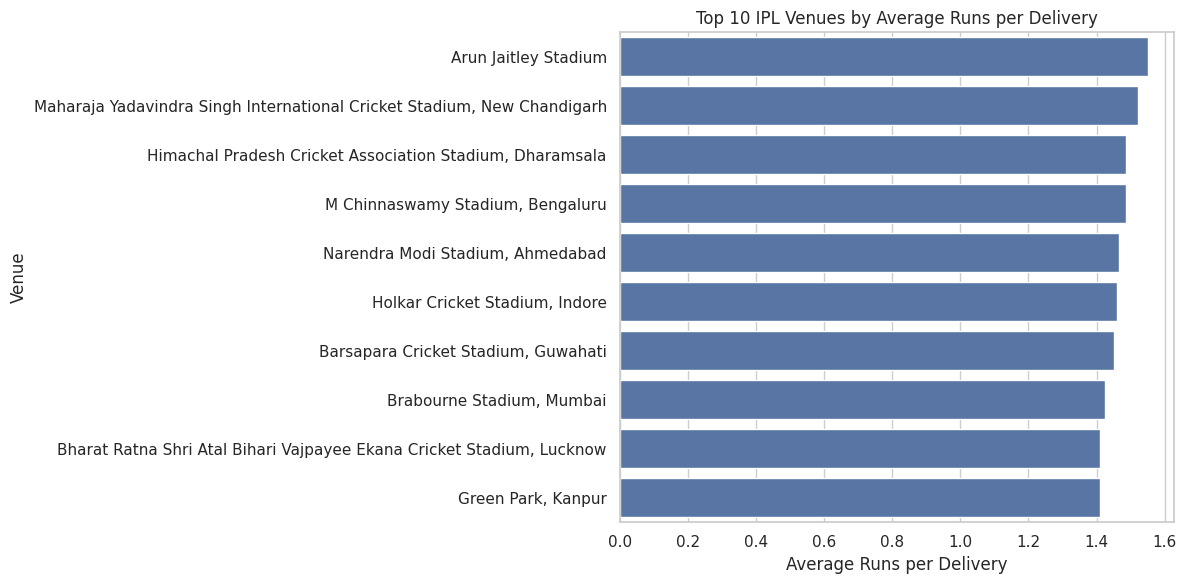

In [33]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=venue_runs.values,
    y=venue_runs.index
)

plt.title("Top 10 IPL Venues by Average Runs per Delivery")
plt.xlabel("Average Runs per Delivery")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

In [34]:
# Convert match dates into datetime format
matches_df["date"] = pd.to_datetime(matches_df["date"])

# Extract year as season
matches_df["season"] = matches_df["date"].dt.year

# Add season information to delivery data
deliveries_df["date"] = pd.to_datetime(deliveries_df["date"])

deliveries_df = deliveries_df.merge(
    matches_df[["match_id", "season"]],
    on="match_id",
    how="left"
)

print("Season information added successfully!")
print("Seasons available:")
print(sorted(deliveries_df["season"].dropna().unique()))

Season information added successfully!
Seasons available:
[np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]


In [35]:
season_runs = (
    deliveries_df.groupby("season")
    .agg(
        Total_Runs=("total_runs", "sum"),
        Total_Deliveries=("total_runs", "count"),
        Total_Matches=("match_id", "nunique")
    )
)

season_runs["Average Runs per Match"] = (
    season_runs["Total_Runs"] /
    season_runs["Total_Matches"]
)

display(season_runs.round(2))

,Total_Runs,Total_Deliveries,Total_Matches,Average Runs per Match
season,,,,
2008,17937,13489,58,309.26
2009,16353,13606,57,286.89
2010,18883,14498,60,314.72
2011,21154,17013,73,289.78
2012,22453,17767,74,303.42
2013,22602,18177,76,297.39
2014,18931,14300,60,315.52
2015,18353,13652,59,311.07
2016,18862,14096,60,314.37


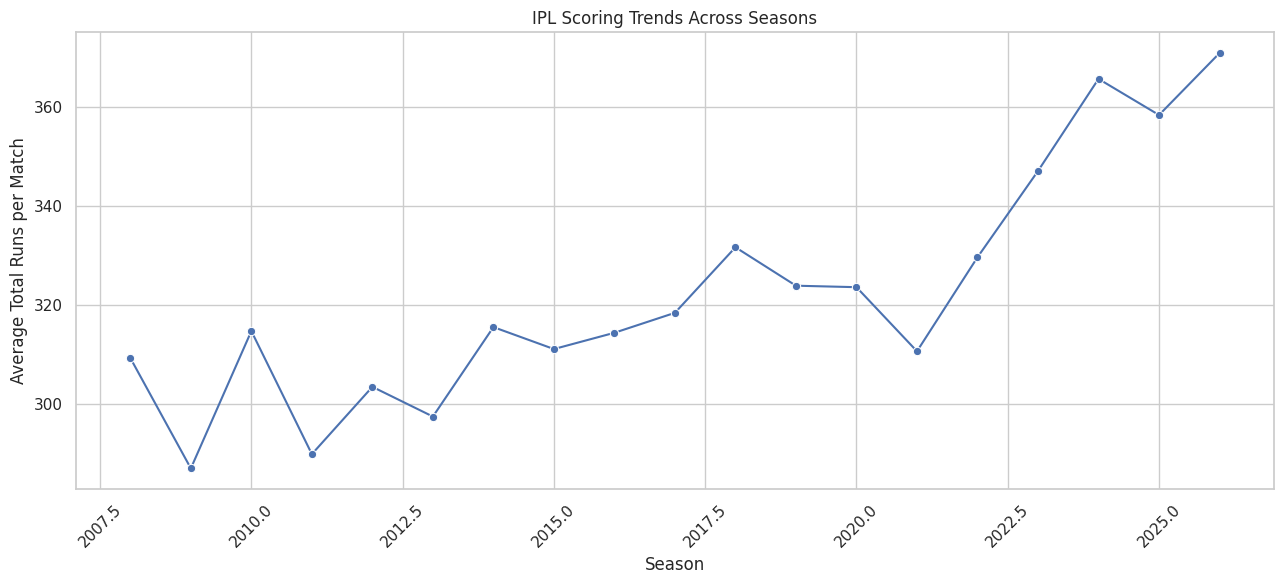

In [36]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=season_runs,
    x=season_runs.index,
    y="Average Runs per Match",
    marker="o"
)

plt.title("IPL Scoring Trends Across Seasons")
plt.xlabel("Season")
plt.ylabel("Average Total Runs per Match")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

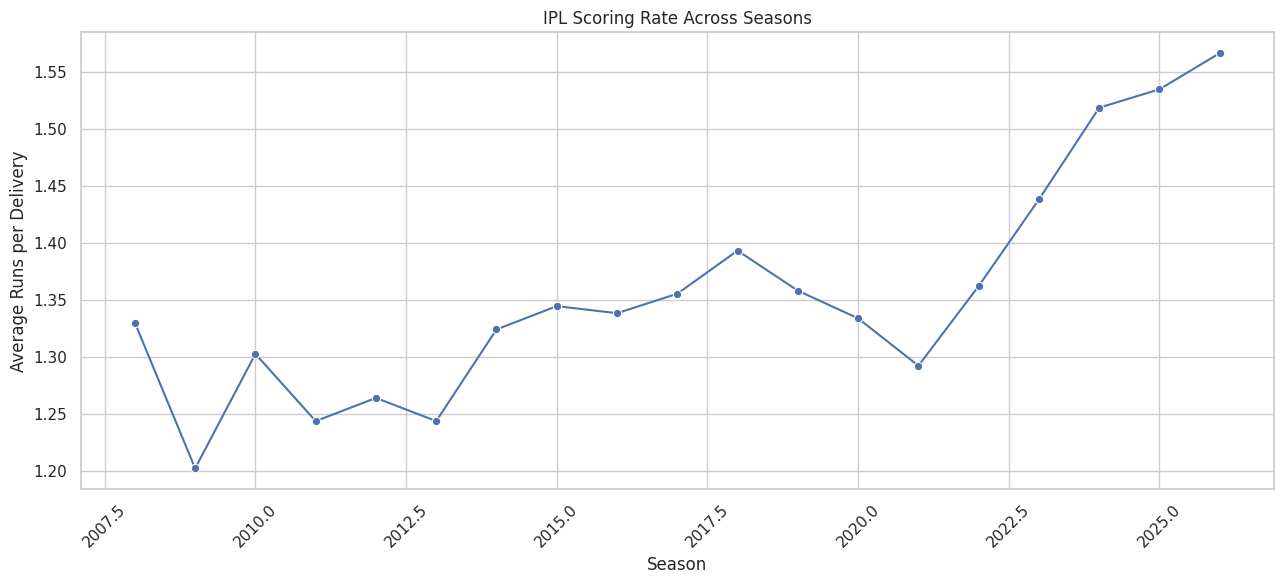

In [37]:
season_runs["Run Rate per Delivery"] = (
    season_runs["Total_Runs"] /
    season_runs["Total_Deliveries"]
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=season_runs,
    x=season_runs.index,
    y="Run Rate per Delivery",
    marker="o"
)

plt.title("IPL Scoring Rate Across Seasons")
plt.xlabel("Season")
plt.ylabel("Average Runs per Delivery")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
innings_stats = deliveries_df.groupby(
    ["match_id", "innings", "batting_team"]
).agg(
    Total_Runs=("total_runs", "sum"),
    Batter_Runs=("batter_runs", "sum"),
    Total_Deliveries=("total_runs", "count"),
    Wickets=("wicket", "sum"),
    Fours=("batter_runs", lambda x: (x == 4).sum()),
    Sixes=("batter_runs", lambda x: (x == 6).sum())
).reset_index()

print("Innings dataset created!")
print("Shape:", innings_stats.shape)

display(innings_stats.head())

Innings dataset created!
Shape: (2514, 9)


,match_id,innings,batting_team,Total_Runs,Batter_Runs,Total_Deliveries,Wickets,Fours,Sixes
0,1082591,1,Sunrisers Hyderabad,207,200,125,4,17,9
1,1082591,2,Royal Challengers Bangalore,172,166,123,10,15,8
2,1082592,1,Mumbai Indians,184,176,125,8,12,11
3,1082592,2,Rising Pune Supergiant,187,183,122,3,18,6
4,1082593,1,Gujarat Lions,183,179,122,4,20,6


In [39]:
correlation_data = innings_stats[
    ["Total_Runs", "Batter_Runs", "Total_Deliveries",
     "Wickets", "Fours", "Sixes"]
]

correlation_matrix = correlation_data.corr()

display(correlation_matrix.round(2))

,Total_Runs,Batter_Runs,Total_Deliveries,Wickets,Fours,Sixes
Total_Runs,1.00,0.99,0.65,-0.09,0.72,0.74
Batter_Runs,0.99,1.00,0.63,-0.11,0.72,0.75
Total_Deliveries,0.65,0.63,1.00,0.36,0.41,0.25
Wickets,-0.09,-0.11,0.36,1.00,-0.14,-0.13
Fours,0.72,0.72,0.41,-0.14,1.00,0.26
Sixes,0.74,0.75,0.25,-0.13,0.26,1.00


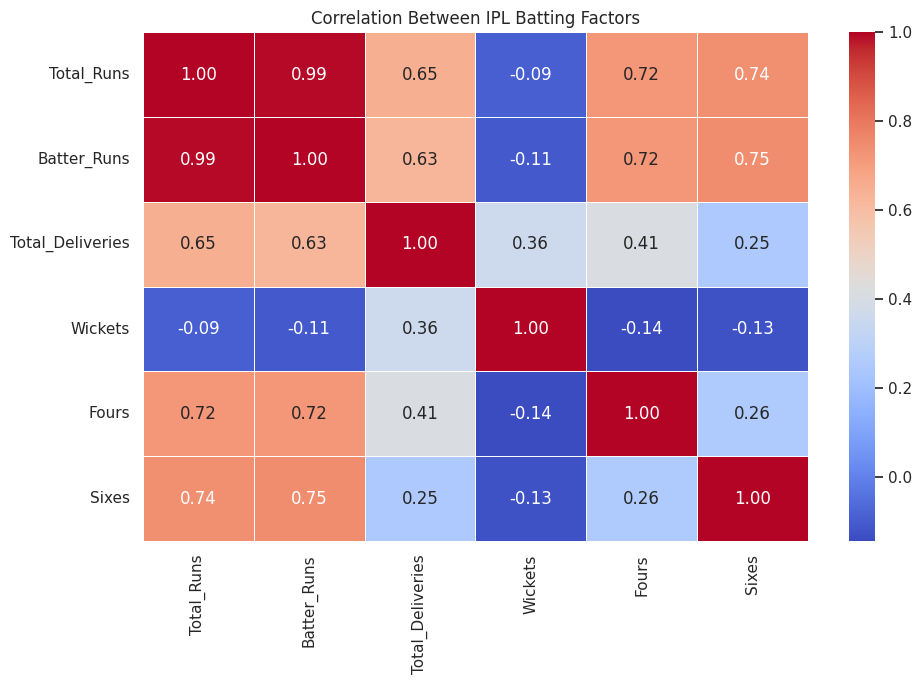

In [40]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between IPL Batting Factors")
plt.tight_layout()
plt.show()

In [41]:
innings_stats["Boundary_Runs"] = (
    innings_stats["Fours"] * 4 +
    innings_stats["Sixes"] * 6
)

innings_stats["Boundary_Percentage"] = (
    innings_stats["Boundary_Runs"] /
    innings_stats["Batter_Runs"].replace(0, np.nan)
) * 100

display(
    innings_stats[
        ["batting_team", "Total_Runs", "Fours",
         "Sixes", "Boundary_Percentage"]
    ].head(10).round(2)
)

,batting_team,Total_Runs,Fours,Sixes,Boundary_Percentage
0,Sunrisers Hyderabad,207,17,9,61.00
1,Royal Challengers Bangalore,172,15,8,65.06
2,Mumbai Indians,184,12,11,64.77
3,Rising Pune Supergiant,187,18,6,59.02
4,Gujarat Lions,183,20,6,64.80
5,Kolkata Knight Riders,184,18,8,71.01
6,Rising Pune Supergiant,163,11,7,54.78
7,Kings XI Punjab,164,11,9,63.64
8,Royal Challengers Bangalore,157,14,7,64.90
9,Delhi Daredevils,142,10,5,51.09


In [42]:
player_sixes = (
    deliveries_df[deliveries_df["batter_runs"] == 6]
    .groupby("batter")
    .size()
    .sort_values(ascending=False)
)

top_10_sixes = player_sixes.head(10)

print("TOP 10 SIX-HITTERS IN IPL")
display(top_10_sixes.reset_index())

TOP 10 SIX-HITTERS IN IPL


,batter,0
0,CH Gayle,359
1,RG Sharma,324
2,V Kohli,317
3,MS Dhoni,264
4,AB de Villiers,253
5,SV Samson,243
6,KL Rahul,239
7,DA Warner,236
8,KA Pollard,224
9,AD Russell,223


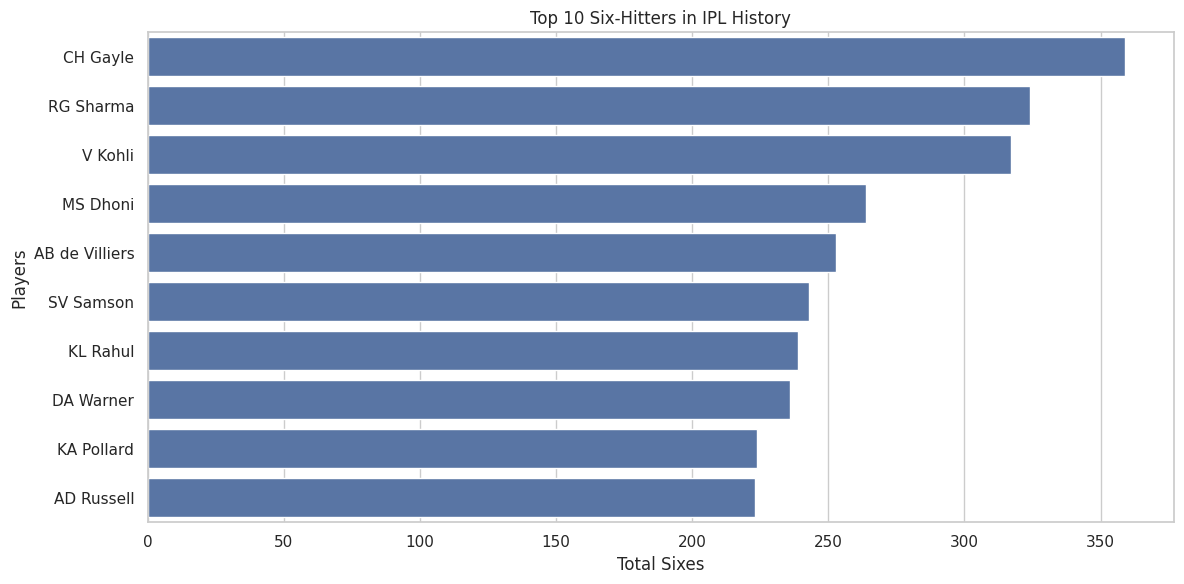

In [43]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_sixes.values,
    y=top_10_sixes.index
)

plt.title("Top 10 Six-Hitters in IPL History")
plt.xlabel("Total Sixes")
plt.ylabel("Players")
plt.tight_layout()
plt.show()

In [44]:
player_fours = (
    deliveries_df[deliveries_df["batter_runs"] == 4]
    .groupby("batter")
    .size()
    .sort_values(ascending=False)
)

top_10_fours = player_fours.head(10)

display(top_10_fours.reset_index())

,batter,0
0,V Kohli,847
1,S Dhawan,768
2,DA Warner,663
3,RG Sharma,661
4,AM Rahane,540
5,KL Rahul,509
6,SK Raina,506
7,G Gambhir,492
8,SA Yadav,482
9,RV Uthappa,481


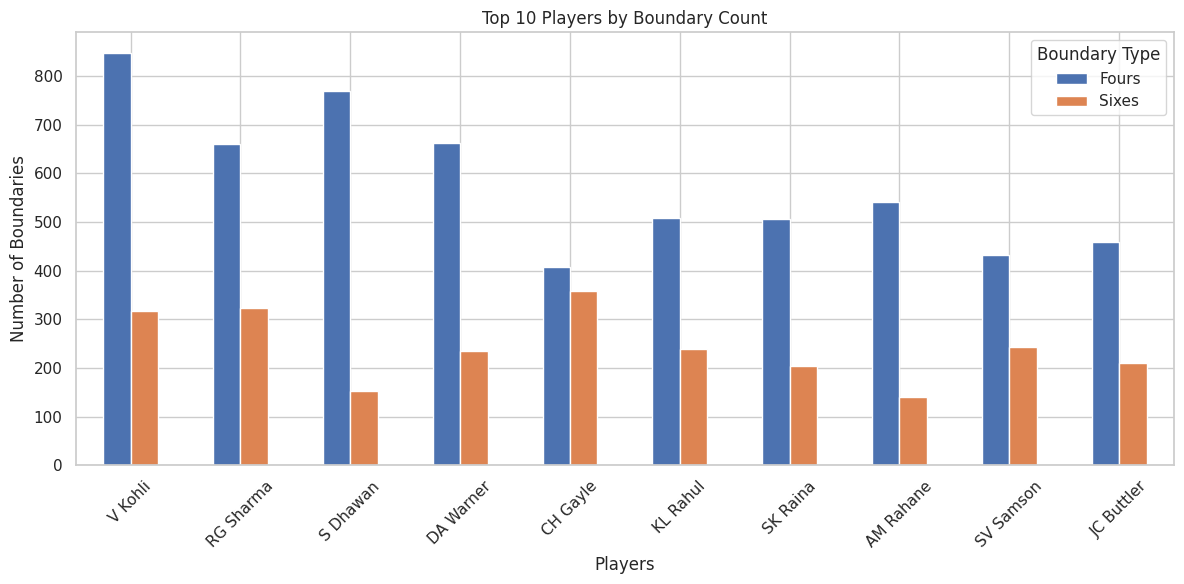

In [45]:
boundary_stats = pd.DataFrame({
    "Fours": player_fours,
    "Sixes": player_sixes
}).fillna(0)

boundary_stats["Total_Boundaries"] = (
    boundary_stats["Fours"] + boundary_stats["Sixes"]
)

top_boundary_players = boundary_stats.sort_values(
    "Total_Boundaries",
    ascending=False
).head(10)

top_boundary_players[["Fours", "Sixes"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Players by Boundary Count")
plt.xlabel("Players")
plt.ylabel("Number of Boundaries")
plt.xticks(rotation=45)
plt.legend(title="Boundary Type")
plt.tight_layout()
plt.show()

In [46]:
innings_scores = deliveries_df.groupby(
    ["match_id", "innings", "batting_team"]
)["total_runs"].sum().reset_index()

innings_scores.rename(
    columns={"total_runs": "innings_runs"},
    inplace=True
)

display(innings_scores.head())

,match_id,innings,batting_team,innings_runs
0,1082591,1,Sunrisers Hyderabad,207
1,1082591,2,Royal Challengers Bangalore,172
2,1082592,1,Mumbai Indians,184
3,1082592,2,Rising Pune Supergiant,187
4,1082593,1,Gujarat Lions,183


In [47]:
first_innings = innings_scores[
    innings_scores["innings"] == 1
][["match_id", "batting_team", "innings_runs"]].copy()

second_innings = innings_scores[
    innings_scores["innings"] == 2
][["match_id", "batting_team", "innings_runs"]].copy()

match_comparison = first_innings.merge(
    second_innings,
    on="match_id",
    suffixes=("_first", "_second")
)

match_comparison["Chasing_Team_Won"] = (
    match_comparison["innings_runs_second"] >
    match_comparison["innings_runs_first"]
)

print("Matches with both innings recorded:", len(match_comparison))
display(match_comparison.head())

Matches with both innings recorded: 1237


,match_id,batting_team_first,innings_runs_first,batting_team_second,innings_runs_second,Chasing_Team_Won
0,1082591,Sunrisers Hyderabad,207,Royal Challengers Bangalore,172,False
1,1082592,Mumbai Indians,184,Rising Pune Supergiant,187,True
2,1082593,Gujarat Lions,183,Kolkata Knight Riders,184,True
3,1082594,Rising Pune Supergiant,163,Kings XI Punjab,164,True
4,1082595,Royal Challengers Bangalore,157,Delhi Daredevils,142,False


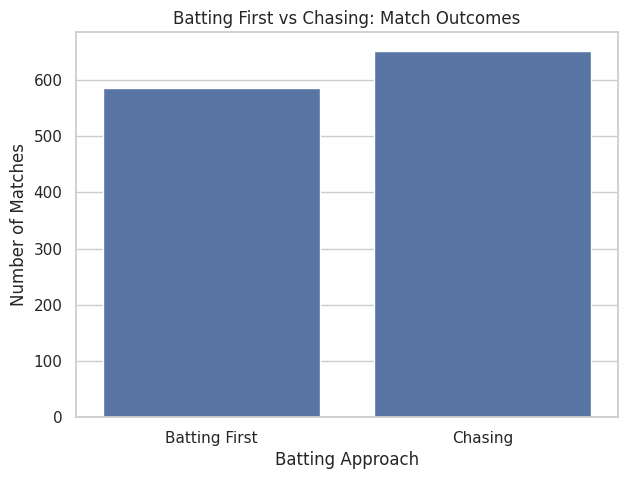

Batting first wins: 585
Chasing wins: 652


In [48]:
chasing_wins = match_comparison["Chasing_Team_Won"].sum()
batting_first_wins = len(match_comparison) - chasing_wins

plt.figure(figsize=(7, 5))

sns.barplot(
    x=["Batting First", "Chasing"],
    y=[batting_first_wins, chasing_wins]
)

plt.title("Batting First vs Chasing: Match Outcomes")
plt.xlabel("Batting Approach")
plt.ylabel("Number of Matches")

plt.show()

print("Batting first wins:", batting_first_wins)
print("Chasing wins:", chasing_wins)

,innings_runs
innings,
1,168.569590
2,155.126112
3,9.312500
4,8.750000
5,11.000000
6,15.000000


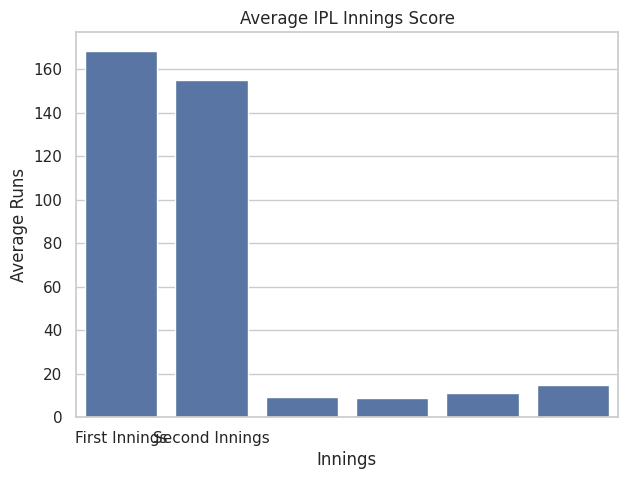

In [49]:
innings_average = innings_scores.groupby(
    "innings"
)["innings_runs"].mean()

display(innings_average)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=innings_average.index.astype(str),
    y=innings_average.values
)

plt.title("Average IPL Innings Score")
plt.xlabel("Innings")
plt.ylabel("Average Runs")
plt.xticks([0, 1], ["First Innings", "Second Innings"])

plt.show()

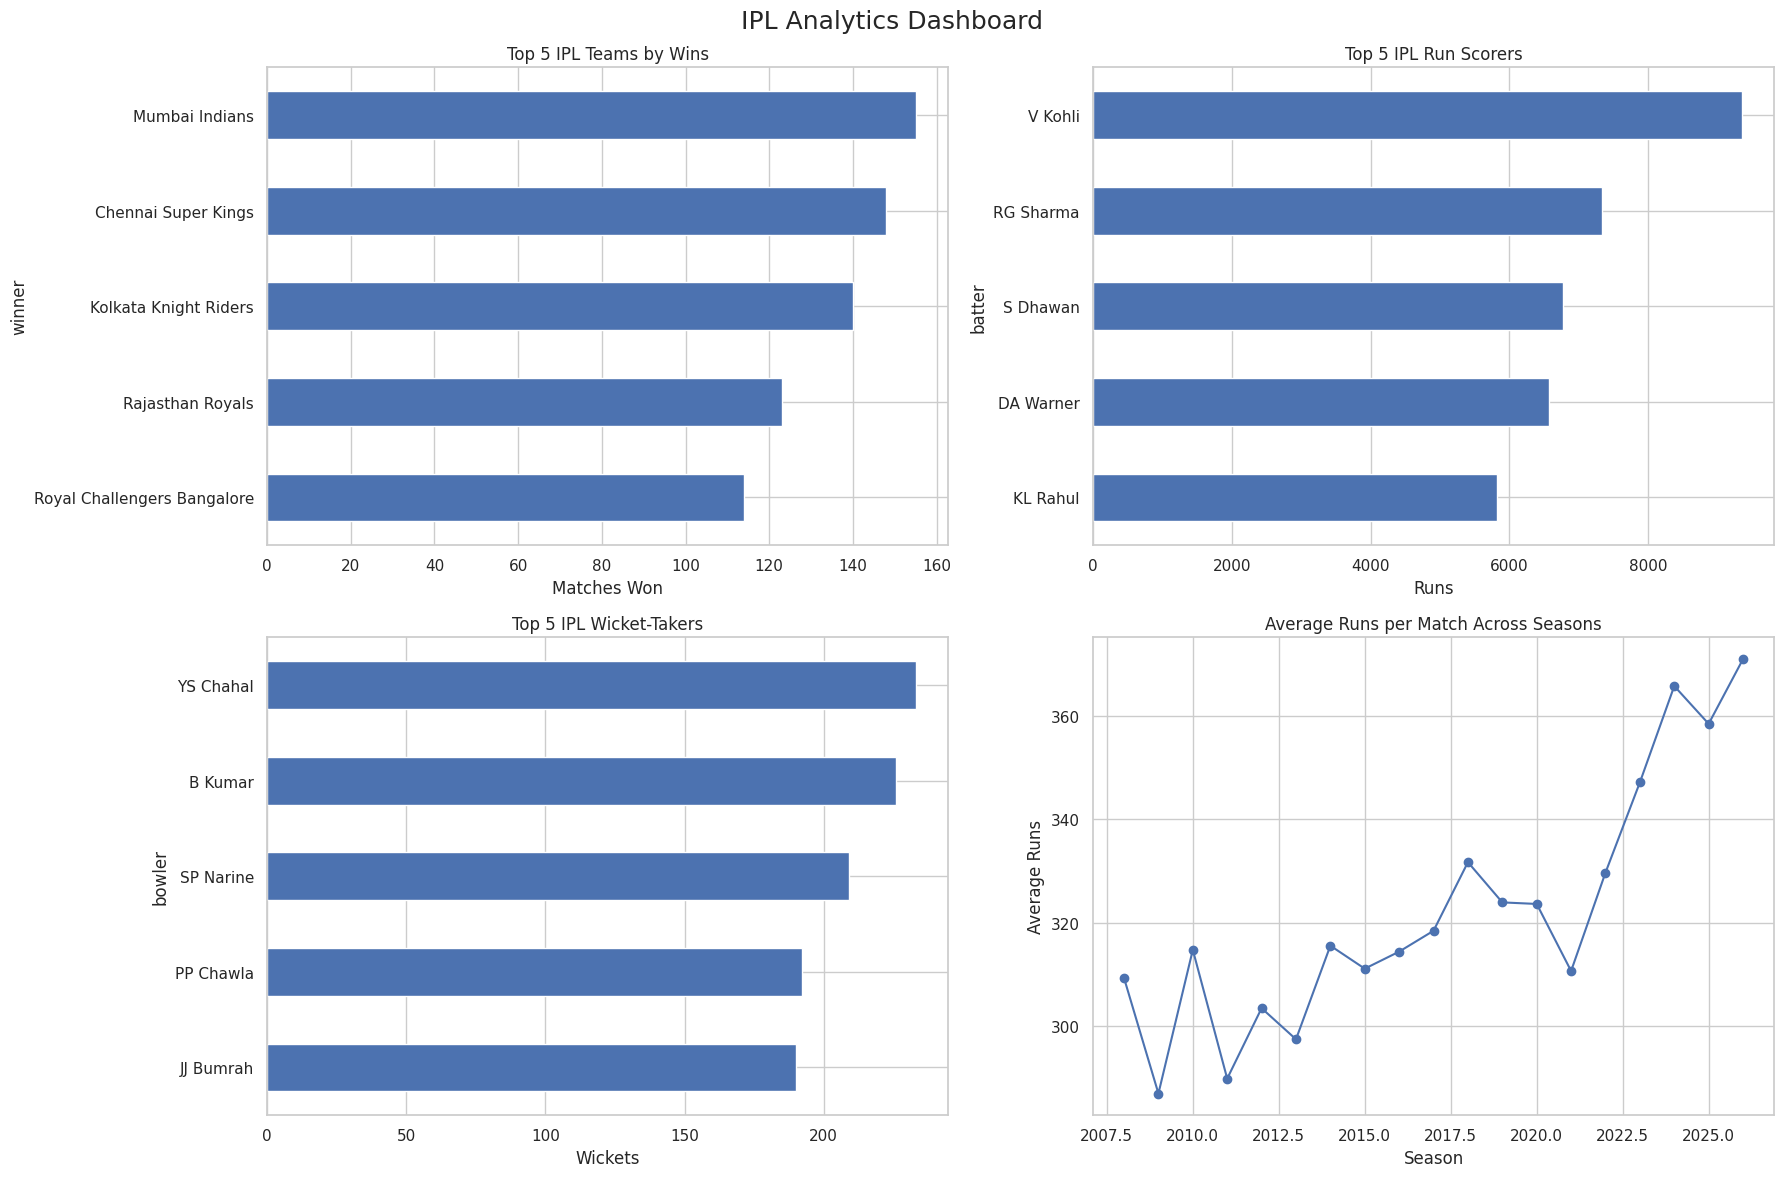

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Top 5 IPL teams
team_wins.head(5).sort_values().plot(
    kind="barh", ax=axes[0, 0]
)
axes[0, 0].set_title("Top 5 IPL Teams by Wins")
axes[0, 0].set_xlabel("Matches Won")

# 2. Top 5 run scorers
top_10_batters.head(5).sort_values().plot(
    kind="barh", ax=axes[0, 1]
)
axes[0, 1].set_title("Top 5 IPL Run Scorers")
axes[0, 1].set_xlabel("Runs")

# 3. Top 5 wicket-takers
top_10_bowlers.head(5).sort_values().plot(
    kind="barh", ax=axes[1, 0]
)
axes[1, 0].set_title("Top 5 IPL Wicket-Takers")
axes[1, 0].set_xlabel("Wickets")

# 4. Scoring trend
axes[1, 1].plot(
    season_runs.index,
    season_runs["Average Runs per Match"],
    marker="o"
)
axes[1, 1].set_title("Average Runs per Match Across Seasons")
axes[1, 1].set_xlabel("Season")
axes[1, 1].set_ylabel("Average Runs")

plt.suptitle("IPL Analytics Dashboard", fontsize=18)
plt.tight_layout()
plt.savefig(
    "IPL_Analysis/visualizations/ipl_analytics_dashboard.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

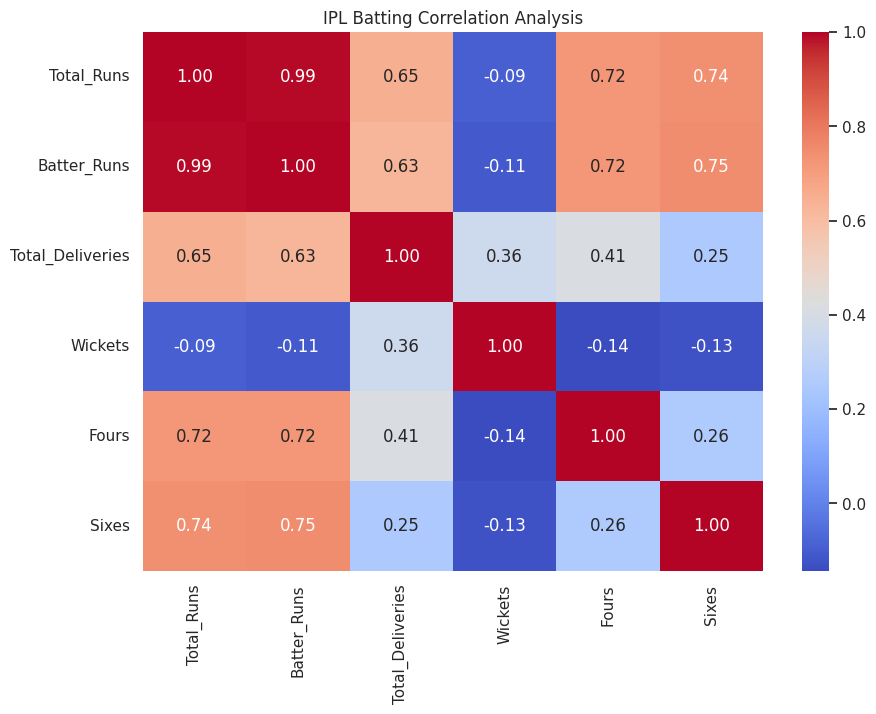

In [51]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("IPL Batting Correlation Analysis")

plt.savefig(
    "IPL_Analysis/visualizations/correlation_heatmap.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

In [52]:
print("=" * 50)
print("IPL DATA ANALYSIS - KEY FINDINGS")
print("=" * 50)

print("\n1. DATASET OVERVIEW")
print("Total Matches:", len(matches_df))
print("Total Deliveries:", len(deliveries_df))
print("Total Teams:", len(all_teams))
print("Total Seasons:", matches_df["season"].nunique())

print("\n2. TEAM PERFORMANCE")
print("Most Successful Team:", team_wins.index[0])
print("Total Wins:", team_wins.iloc[0])

print("\n3. BATTING PERFORMANCE")
print("Highest Run Scorer:", player_runs.index[0])
print("Total Runs:", player_runs.iloc[0])

print("\n4. BOWLING PERFORMANCE")
print("Leading Wicket Taker:", bowler_wickets.index[0])
print("Total Wickets:", bowler_wickets.iloc[0])

print("\n5. TOSS ANALYSIS")
print("Toss-to-Match Win Percentage:",
      round(toss_win_percentage, 2), "%")

print("\n6. SCORING TRENDS")
print("Highest Average Scoring Season:",
      season_runs["Average Runs per Match"].idxmax())

print("\n7. BOUNDARY ANALYSIS")
print("Most Sixes:", player_sixes.index[0])
print("Total Sixes:", player_sixes.iloc[0])

print("\n" + "=" * 50)

IPL DATA ANALYSIS - KEY FINDINGS

1. DATASET OVERVIEW
Total Matches: 1243
Total Deliveries: 295732
Total Teams: 19
Total Seasons: 19

2. TEAM PERFORMANCE
Most Successful Team: Mumbai Indians
Total Wins: 155

3. BATTING PERFORMANCE
Highest Run Scorer: V Kohli
Total Runs: 9346

4. BOWLING PERFORMANCE
Leading Wicket Taker: YS Chahal
Total Wickets: 233

5. TOSS ANALYSIS
Toss-to-Match Win Percentage: 51.56 %

6. SCORING TRENDS
Highest Average Scoring Season: 2026

7. BOUNDARY ANALYSIS
Most Sixes: CH Gayle
Total Sixes: 359



In [53]:
os.makedirs("IPL_Analysis/reports", exist_ok=True)

team_performance.to_csv(
    "IPL_Analysis/reports/team_performance.csv"
)

batting_stats.to_csv(
    "IPL_Analysis/reports/batting_statistics.csv"
)

bowling_stats.to_csv(
    "IPL_Analysis/reports/bowling_statistics.csv"
)

season_runs.to_csv(
    "IPL_Analysis/reports/season_scoring_trends.csv"
)

innings_stats.to_csv(
    "IPL_Analysis/reports/innings_statistics.csv",
    index=False
)

print("Analysis tables exported successfully!")

Analysis tables exported successfully!
